In [1]:
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Conv2D,Activation,Dropout,Flatten,MaxPooling2D
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.utils import to_categorical
from scikeras.wrappers import KerasClassifier
import seaborn as sns
from sklearn.metrics import confusion_matrix

I0000 00:00:1793818457.634543    7198 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793818457.997342    7198 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793818459.827592    7198 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
(x_train_digit,y_train_digit),(x_test_digit,y_test_digit) = fashion_mnist.load_data()
print("x_train:",x_train_digit.shape)
print("y_train:",y_train_digit.shape)
print("x_test:",x_test_digit.shape)
print("y_test:",y_test_digit.shape)

x_train: (60000, 28, 28)
y_train: (60000,)
x_test: (10000, 28, 28)
y_test: (10000,)


In [3]:
x_train_digit

array([[[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       ...,

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 

In [4]:
y_train_digit

array([9, 0, 0, ..., 3, 0, 5], shape=(60000,), dtype=uint8)

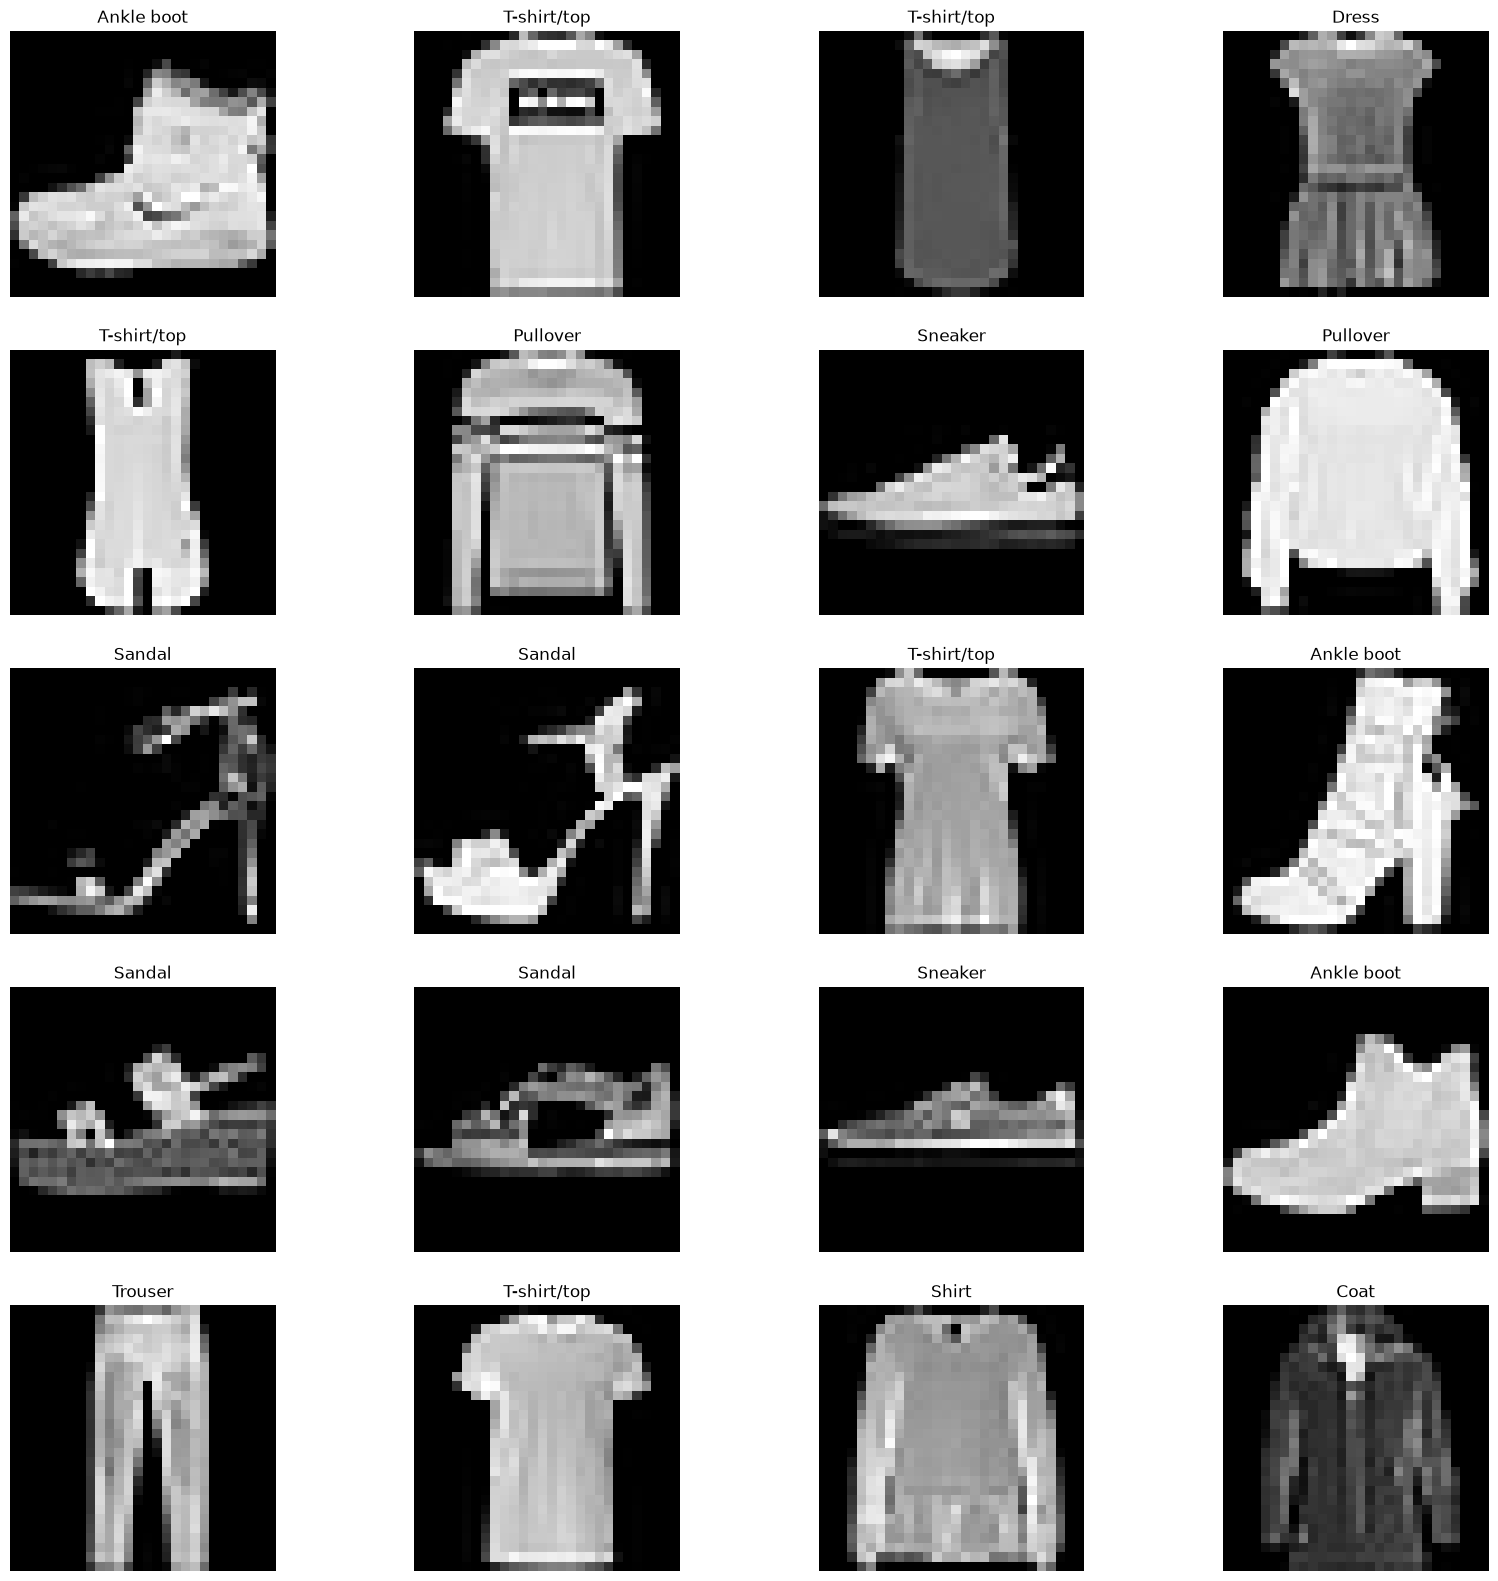

In [5]:
mnist_names = [
    "T-shirt/top","Trouser","Pullover","Dress","Coat","Sandal","Shirt","Sneaker","Bag","Ankle boot"
]	
plt.figure(figsize=(20, 20))
for i in range(20):
    plt.subplot(5, 4, i + 1)
    plt.axis('off')
    plt.grid(False)
    plt.imshow(x_train_digit[i], cmap='gray')
    plt.title(mnist_names[y_train_digit[i]])
plt.show()

In [6]:
x_train=x_train_digit.reshape(x_train_digit.shape[0],28,28,1)
x_test=x_test_digit.reshape(x_test_digit.shape[0],28,28,1)

In [7]:
x_train=x_train.astype('float32')
x_test=x_test.astype('float32')

In [8]:
x_train /= 255
x_test /= 255

In [9]:
model=Sequential()
model.add(Conv2D(28,kernel_size=(3,3),input_shape=(28,28,1),activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Flatten())
model.add(Dense(128,activation=tf.nn.relu))
model.add(Dense(10,activation=tf.nn.softmax))

/home/lokesh/Loki/Projects/GEN AI/.venv/lib/python3.14/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1793818462.632112    7198 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



In [10]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [11]:
history = model.fit(
    x_train,
    y_train_digit,
    batch_size=100,
    epochs=10,
    validation_data=(x_test,y_test_digit)
)

W0000 00:00:1793818462.824578    7198 cpu_allocator_impl.cc:174] Allocation of 188160000 exceeds 10% of free system memory.


Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.8464 - loss: 0.4372 - val_accuracy: 0.8809 - val_loss: 0.3362
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 11s 19ms/step - accuracy: 0.8964 - loss: 0.2930 - val_accuracy: 0.8898 - val_loss: 0.3024
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 11s 19ms/step - accuracy: 0.9081 - loss: 0.2540 - val_accuracy: 0.9033 - val_loss: 0.2730
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 11s 19ms/step - accuracy: 0.9189 - loss: 0.2222 - val_accuracy: 0.9023 - val_loss: 0.2661
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 11s 19ms/step - accuracy: 0.9281 - loss: 0.1982 - val_accuracy: 0.9051 - val_loss: 0.2551
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 11s 19ms/step - accuracy: 0.9344 - loss: 0.1789 - val_accuracy: 0.9085 - val_loss: 0.2524
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 11s 19ms/step - accuracy: 0.9409 - loss: 0.1607 - val_accuracy: 0.9119 - val_loss: 0.2584
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 11s 19ms/step - accuracy: 0.9463 - loss: 0.1458 - 

In [12]:
y_predict = model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [13]:
y_predict[2]

array([7.8586183e-08, 9.9999982e-01, 4.6942822e-10, 8.1590352e-09,
       1.1621542e-09, 4.3868368e-12, 5.7659246e-09, 1.0897703e-13,
       1.3163198e-10, 4.3556547e-12], dtype=float32)

In [14]:
import numpy as np
y_predicted = np.argmax(y_predict, axis=1)

In [15]:
y_actual = y_test_digit
y_pred = model.predict(x_test)
y_predicted = np.argmax(y_pred, axis=1)
print("Actual:", y_actual[0])
print("Predicted:", y_predicted[0])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Actual: 9
Predicted: 9


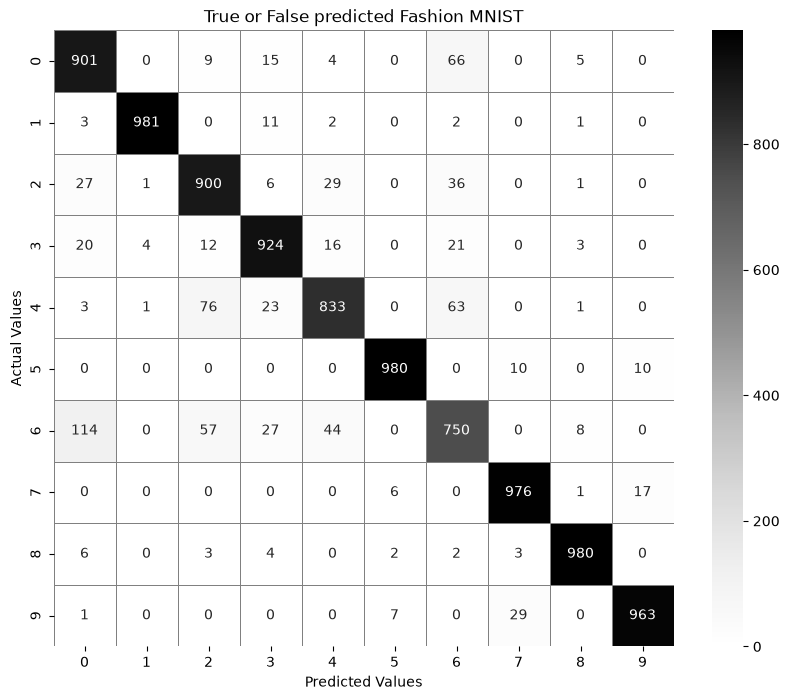

In [20]:
cm = confusion_matrix(y_actual, y_predicted)
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    cmap='Greys',
    fmt='d',
    linewidths=0.5,
    linecolor='gray'
)
plt.title('True or False predicted Fashion MNIST')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.show()

In [17]:
from sklearn.metrics import classification_report
print(classification_report(y_actual, y_predicted))

              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1000
           1       0.99      0.98      0.99      1000
           2       0.85      0.90      0.88      1000
           3       0.91      0.92      0.92      1000
           4       0.90      0.83      0.86      1000
           5       0.98      0.98      0.98      1000
           6       0.80      0.75      0.77      1000
           7       0.96      0.98      0.97      1000
           8       0.98      0.98      0.98      1000
           9       0.97      0.96      0.97      1000

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.92     10000
weighted avg       0.92      0.92      0.92     10000



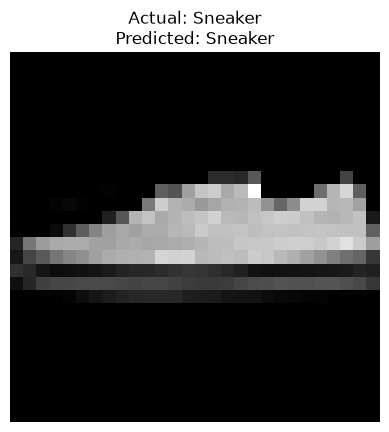

In [18]:
mnist_names = [
    "T-shirt/top","Trouser","Pullover","Dress","Coat","Sandal","Shirt","Sneaker","Bag","Ankle boot"
]	
index = 789
actual = y_test_digit[index]
predicted = np.argmax(y_predict[index])
plt.imshow(x_test_digit[index].reshape(28, 28), cmap='gray')
plt.title(
    f"Actual: {mnist_names[actual]}\n"
    f"Predicted: {mnist_names[predicted]}"
)
plt.axis('off')
plt.show()
